## Current public benchmark target (version2)
The scored target is the unique constrained SOLA objective defined in README. Its independent full dual solve is the numerical reference; the local active reconstruction uses a converged Krylov solve. The separately plotted original1000-step result is a historical approximation, not physical ground truth. Its maximum difference from the exact mathematical target is0.0172369nHz, which exceeded the previous implementation-bound field tolerance. The current thresholds are unchanged; convergence is improved instead. All original comparisons, six parameter/iteration ablations and32actual noise perturbations remain below.


# Solar interior rotation: localized estimates from global oscillations

This notebook freshly reconstructs the complete native 29,617-observation acquisition on all 101×51 points with 1,500 Lanczos steps for convergence to the public mathematical target. The scientific unknown is cyclic rotation, not brightness or surface magnetic field. There is **no supplied true interior rotation**. The original-method field is an independently reproduced numerical reference, not ground truth.

## 1. Observation and known solar calibration

Rotation shifts acoustic oscillation frequencies. The supplied factorized kernels encode each measured coefficient's sensitivity to the equator-symmetric rotation field. They were computed from a fixed structural/eigenfunction model independently of the target rotation. The author observation table's identifier is mt1.252_000.2d; the released files do not state its observing dates. All observations and all spatial boundaries remain in the benchmark.

Active shared Python: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6
Observations: 29617 field: (101, 51) known kernel blocks: 293


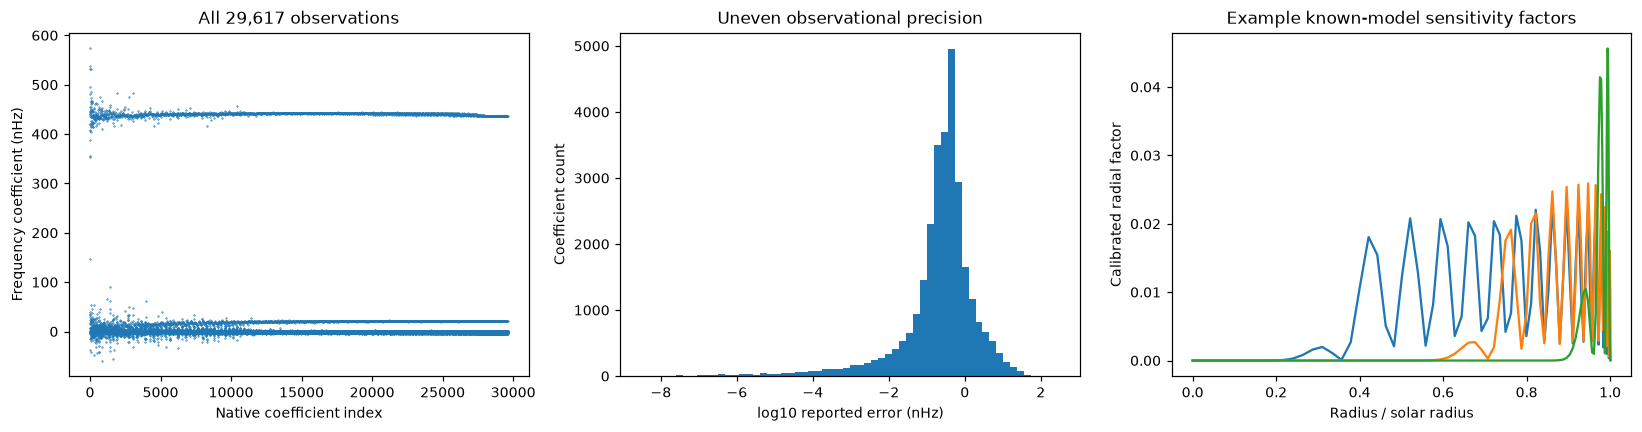

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').is_dir():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.main import run
from src.physics_model import RotationOperator,ConstrainedOperator
from src.solvers import invert_from_basis,apply_measurements
from src.visualization import observations,field_comparison,resolution,residuals
data=load_data(root/'data/raw_data.npz');op=RotationOperator(data);con=ConstrainedOperator(op)
print('Active shared Python:',sys.executable,'NumPy:',np.__version__)
print('Observations:',op.nm,'field:',(op.nr,op.nt),'known kernel blocks:',len(op.blocks))
plt.rcParams.update({'figure.dpi':110,'font.size':9})
observations(data);plt.show()

## 2. Physical operator and the implemented inverse

For each measured coefficient the local forward operator contracts the given radial/angular sensitivity factors with the entire field, producing $y=Kx+\epsilon$. Here $y$ is the observed frequency vector, $x$ is cyclic rotation in nHz, $K$ is the known integrated sensitivity operator, and $\epsilon$ is measurement error. Error whitening divides by reported standard deviations.

SOLA estimates a normalized localized average by choosing observation weights $q$ to minimize

$$
\|W^{-1/2}\widetilde K^Tq-W^{1/2}T\|_2^2+\mu\|q\|_2^2,
\qquad q^T\widetilde K\mathbf1=1.
$$

Here $\widetilde K$ is the error-whitened operator, $W$ contains the meridional quadrature weights, $T$ is a normalized equator-symmetric Gaussian target, and $\mu=3$ penalizes noise amplification. Radial target width is .06 times known-model sound speed relative to radius .7; angular width is .1 radians. A Householder constraint reduction followed by 1,000 fully reorthogonalized Golub–Kahan steps computes a reusable calibration subspace. Every target is solved in that fresh subspace. Core acquisition, target, constraint, iteration and reduced inverse mathematics are local code.

Lanczos 1/1500
Lanczos 100/1500
Lanczos 200/1500
Lanczos 300/1500
Lanczos 400/1500
Lanczos 500/1500
Lanczos 600/1500
Lanczos 700/1500
Lanczos 800/1500
Lanczos 900/1500
Lanczos 1000/1500
Lanczos 1100/1500
Lanczos 1200/1500
Lanczos 1300/1500
Lanczos 1400/1500
Lanczos 1500/1500
Fresh complete benchmark runtime (s): 28.7951832000399


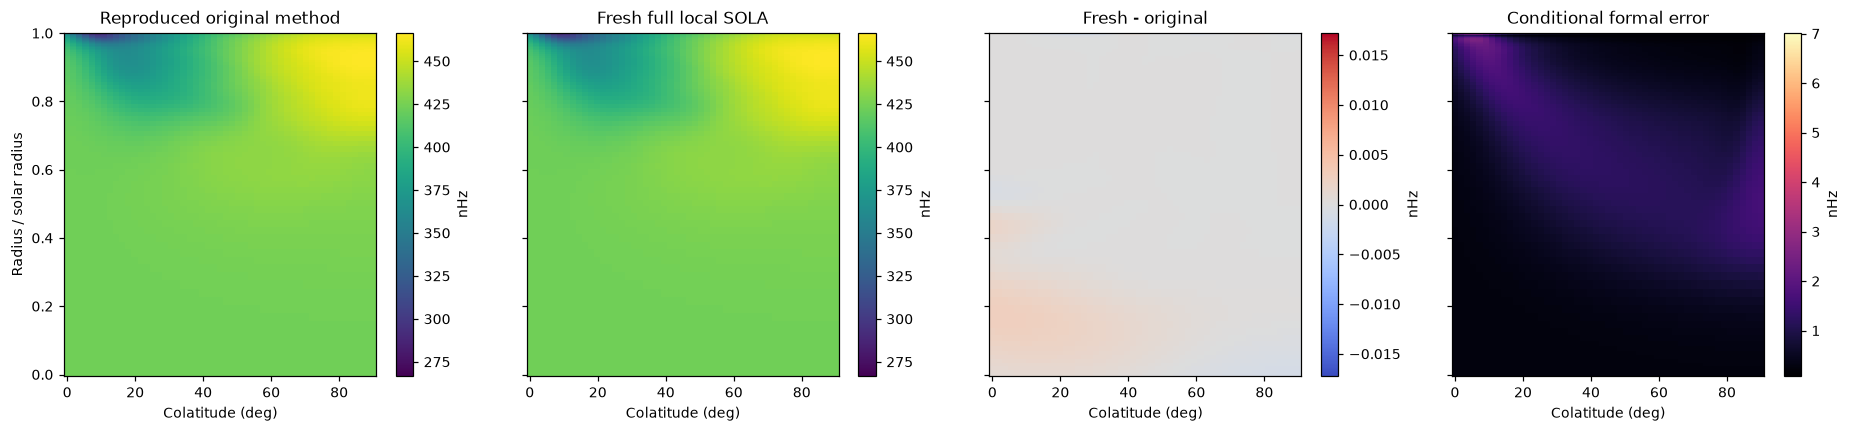

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "rotation_max_abs_nHz": 6.9802183588763e-08,
    "observation_weighted_rms": 1.1936132279167608
  },
  "thresholds": {
    "rotation_max_abs_nHz": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "observation_weighted_rms": {
      "comparison": "<=",
      "boundary": 1.2
    }
  },
  "errors": []
}


In [2]:
started=time.perf_counter()
fresh,diagnostics,runtime=run(root/'data/raw_data.npz',root/'output/reconstruction.npz',progress=True)
print('Fresh complete benchmark runtime (s):',runtime)
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as a:upstream={k:a[k].copy() for k in a.files}
field_comparison(data,fresh,upstream,diagnostics['formal_error']);plt.show()
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate(root/'output/reconstruction.npz');assert exitcode==0,report
print(json.dumps(report,indent=2))

## 3. Recovery, reference and uncertainty interpretation

The first two maps compare a reproduced original solution with this fresh local inverse. Their difference measures the historical1000-step approximation against the converged1500-step target. A separately executed original1500-step run agrees with the local1500-step implementation within6.49e-11nHz. It does not show physical error against the Sun. Conditional formal errors propagate the supplied diagonal frequency-error model with the structural model fixed; they exclude calibration/model bias.

The radial and angular sections below show the spatial variation actually recovered from the observations. Narrow formal error bands should not be mistaken for sharp spatial resolution. In poorly localized regions, SOLA can report a precise broad average instead of a local point measurement.

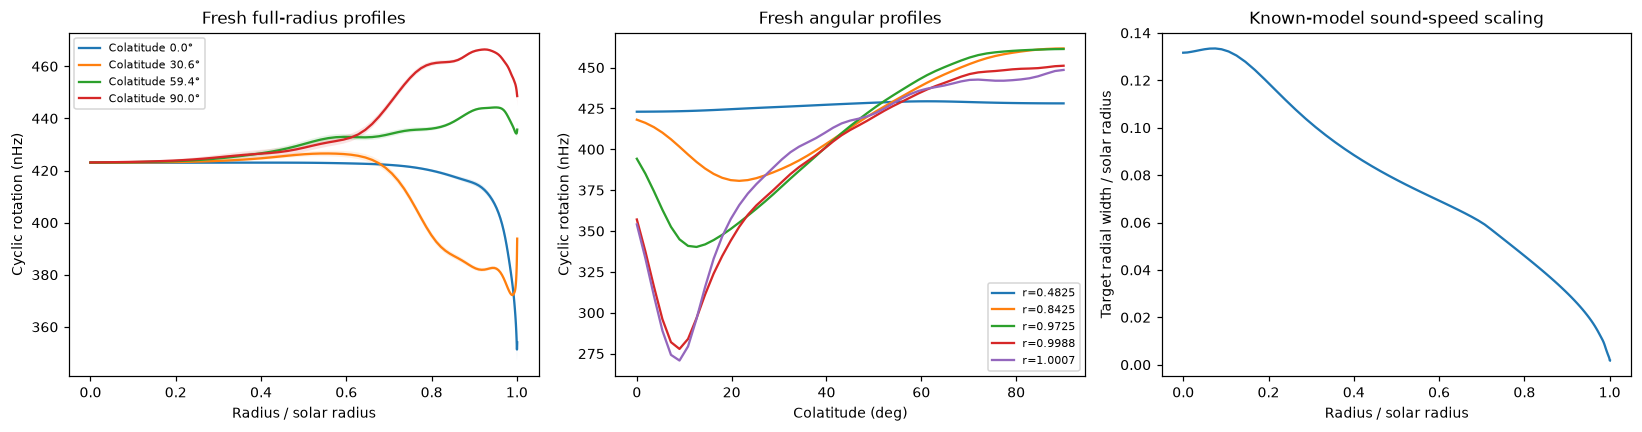

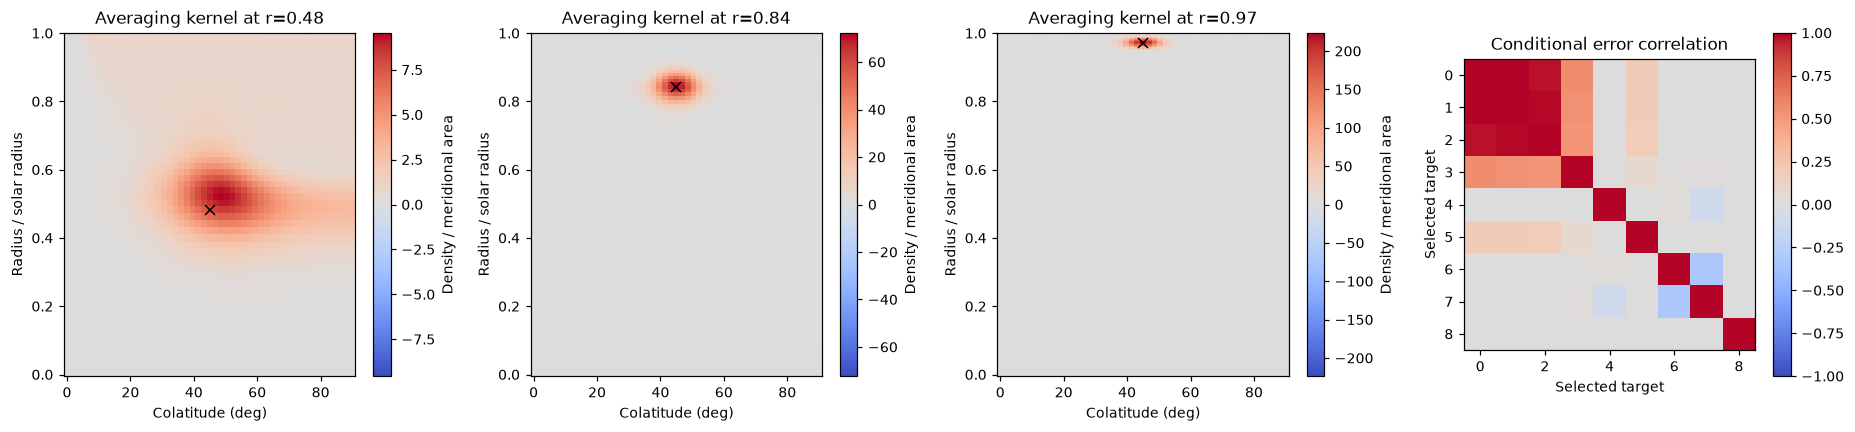

Selected-kernel integrals: [1. 1. 1. 1. 1. 1. 1. 1. 1.]
Constant-rotation estimator response: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [3]:
radius=data['mesh'][::51,0];theta=np.rad2deg(data['mesh'][:51,1]);field=fresh['reconstruction'][0];err=diagnostics['formal_error']
fig,ax=plt.subplots(1,3,figsize=(15,4))
for j in [0,17,33,50]:
    ax[0].plot(radius,field[:,j],label=f'Colatitude {theta[j]:.1f}°')
    ax[0].fill_between(radius,field[:,j]-err[:,j],field[:,j]+err[:,j],alpha=.12)
ax[0].set(xlabel='Radius / solar radius',ylabel='Cyclic rotation (nHz)',title='Fresh full-radius profiles');ax[0].legend(fontsize=7)
for j in [26,50,70,90,100]:ax[1].plot(theta,field[j],label=f'r={radius[j]:.4f}')
ax[1].set(xlabel='Colatitude (deg)',ylabel='Cyclic rotation (nHz)',title='Fresh angular profiles');ax[1].legend(fontsize=7)
ax[2].plot(radius,diagnostics['radial_widths']);ax[2].set(xlabel='Radius / solar radius',ylabel='Target radial width / solar radius',title='Known-model sound-speed scaling')
fig.tight_layout();plt.show()
resolution(data,diagnostics);plt.show()
print('Selected-kernel integrals:',diagnostics['averaging_kernels'].reshape(-1,5151)@op.weight)
print('Constant-rotation estimator response:',diagnostics['estimator_coefficients']@op.forward(np.ones(5151)))

## 4. Full observation residual and physical checks

The calibrated forward operator acts on the recovered field and predicts every observed coefficient. The weighted RMS below uses each reported frequency uncertainty and no fitted scale. A unit Gaussian is a diagnostic comparison, not a claim that all modeling residuals are independent Gaussian noise. Resolution kernels and correlated errors provide additional evidence about what the field means.

The adjoint check below uses independently generated numerical vectors to verify the forward/transpose identity. The constant-rotation test checks the estimator's physical normalization.

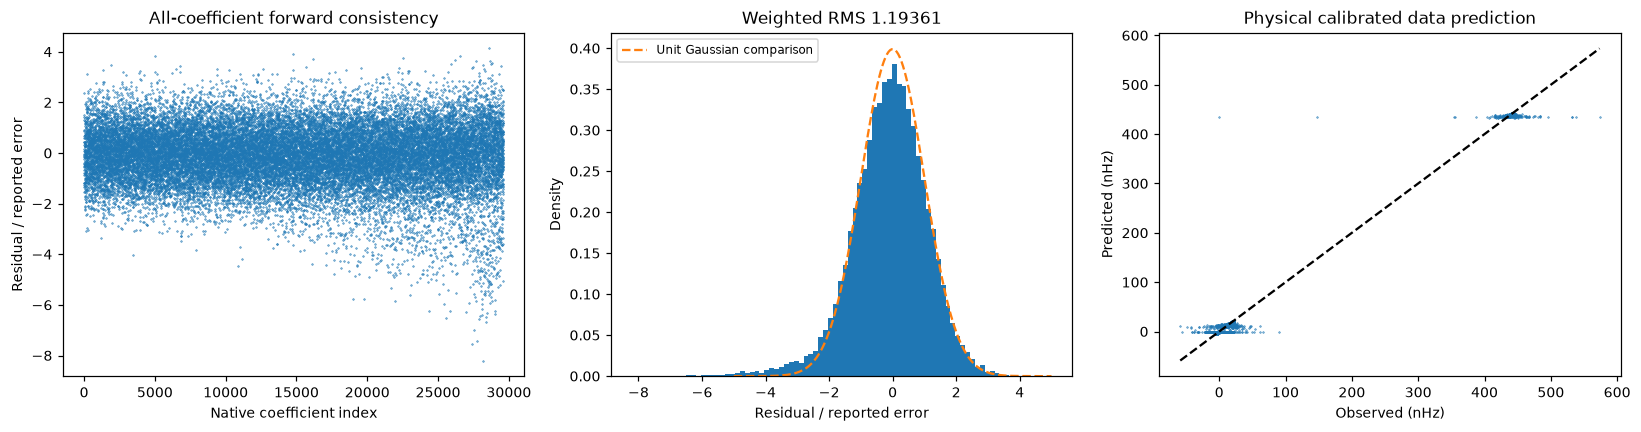

Adjoint relative discrepancy: 1.036931671369147e-15
Maximum fresh field difference from original (nHz): 0.017236849722223724
Maximum conditional formal-error difference (nHz): 3.161512226101948e-05


In [4]:
predicted=op.forward(field,whiten=False);sigma=np.abs(data['splitting_error']);sigma=np.where(sigma==0,1.,sigma)
residuals(data['splittings'],predicted,sigma);plt.show()
rng=np.random.default_rng(2901);x=rng.normal(size=5151);y=rng.normal(size=29617)
lhs=float(np.dot(op.forward(x),y));rhs=float(np.dot(x,op.adjoint(y)))
adjoint_error=abs(lhs-rhs)/max(abs(lhs),abs(rhs),1e-30)
print('Adjoint relative discrepancy:',adjoint_error)
print('Maximum fresh field difference from original (nHz):',np.max(abs(field-upstream['reconstruction'][0])))
print('Maximum conditional formal-error difference (nHz):',np.max(abs(err-upstream['formal_error'][0])))

## 5. Iteration, tradeoff and resolution ablations

All alternatives below are computed using the fresh acquisition subspace. Prefixes of the freshly computed1,500-step Golub–Kahan factorization are the corresponding 250/500-step factorizations; no archived basis or result is loaded. Regularization and target widths are method choices, and the public objective fixes the benchmark setting. Their effects on observed-data consistency, target resolution, propagated error and field stability are measured separately.

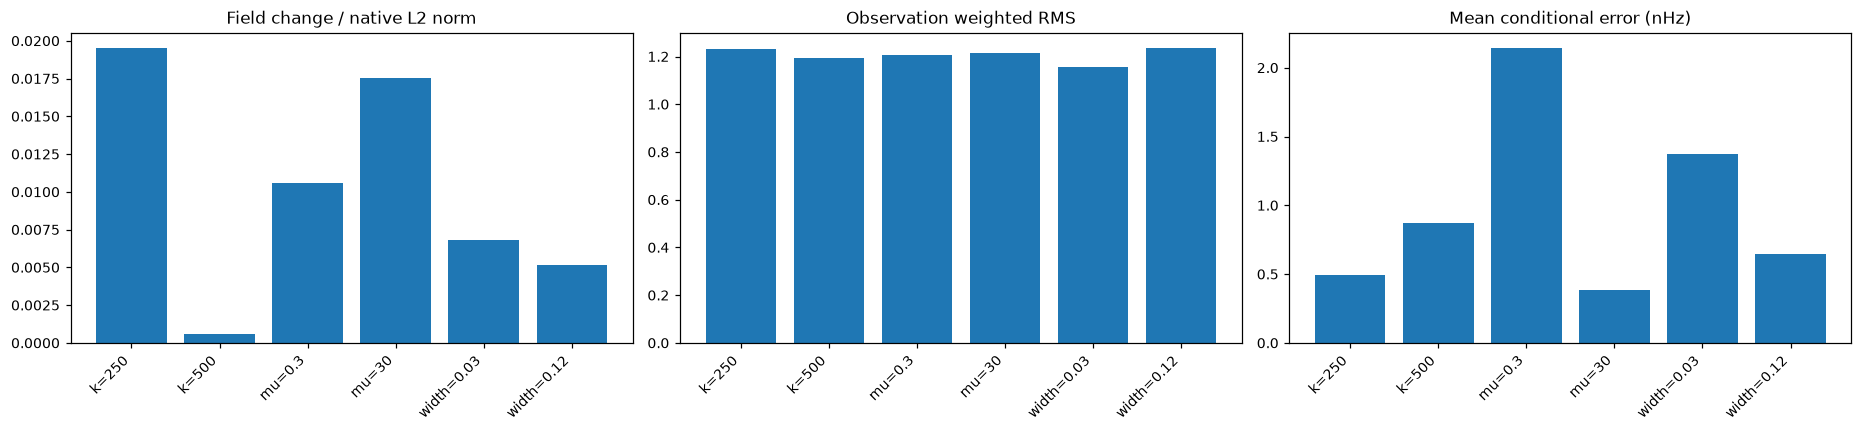

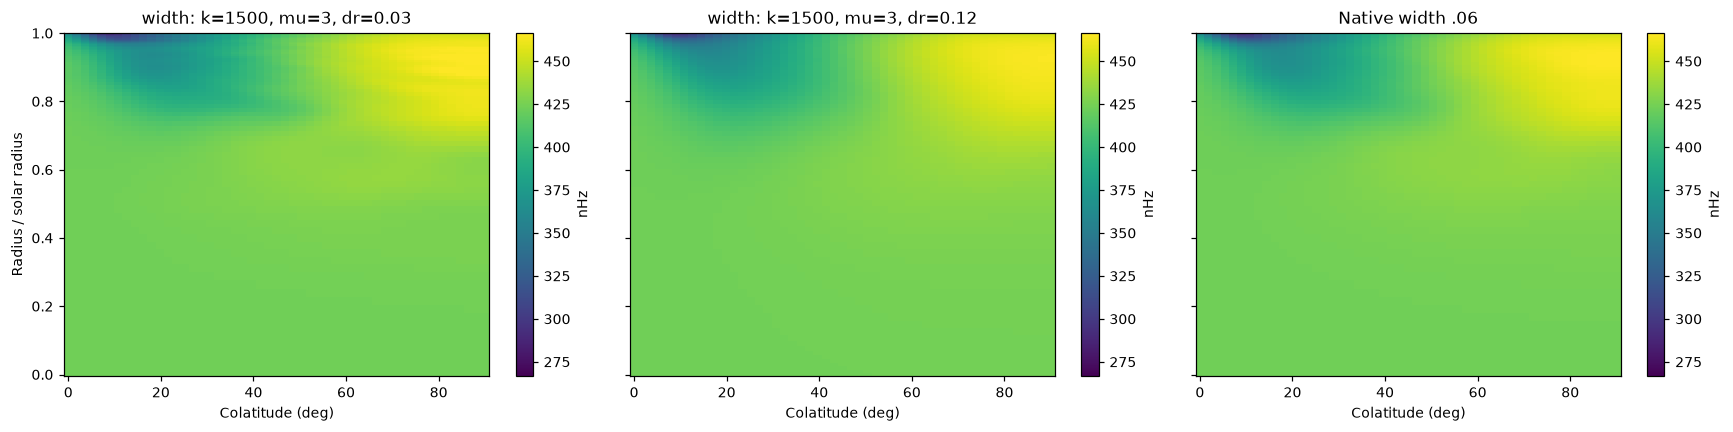

{'label': 'iterations: k=250, mu=3, dr=0.06', 'iterations': 250, 'tradeoff': 3.0, 'width': 0.06, 'field_relative_change': 0.019548672303057565, 'weighted_rms': 1.2328926123560198, 'mean_formal_error': 0.4952570750609725}
{'label': 'iterations: k=500, mu=3, dr=0.06', 'iterations': 500, 'tradeoff': 3.0, 'width': 0.06, 'field_relative_change': 0.000566085818889542, 'weighted_rms': 1.1950739028774668, 'mean_formal_error': 0.8712307785451446}
{'label': 'tradeoff: k=1500, mu=0.3, dr=0.06', 'iterations': 1500, 'tradeoff': 0.3, 'width': 0.06, 'field_relative_change': 0.01055481842352083, 'weighted_rms': 1.2050177528030344, 'mean_formal_error': 2.146358994769728}
{'label': 'tradeoff: k=1500, mu=30, dr=0.06', 'iterations': 1500, 'tradeoff': 30.0, 'width': 0.06, 'field_relative_change': 0.01753995358307862, 'weighted_rms': 1.2140343742196902, 'mean_formal_error': 0.3837539999273898}
{'label': 'width: k=1500, mu=3, dr=0.03', 'iterations': 1500, 'tradeoff': 3.0, 'width': 0.03, 'field_relative_chang

In [5]:
ablation=[];ablation_fields={}
settings=[('iterations',250,3.,.06),('iterations',500,3.,.06),('tradeoff',1500,.3,.06),('tradeoff',1500,30.,.06),('width',1500,3.,.03),('width',1500,3.,.12)]
for group,k,mu,width in settings:
    out,dd=invert_from_basis(data,con,diagnostics['U'][:,:k+1],diagnostics['V'][:,:k],diagnostics['alpha'][:k],diagnostics['beta'][:k],tradeoff=mu,width=width)
    reconstructed=out['reconstruction'][0]
    weighted=(op.forward(reconstructed,whiten=False)-data['splittings'])/sigma
    label=f'{group}: k={k}, mu={mu:g}, dr={width:g}'
    ablation.append(dict(label=label,iterations=k,tradeoff=mu,width=width,field_relative_change=float(np.linalg.norm(reconstructed-field)/np.linalg.norm(field)),weighted_rms=float(np.sqrt(np.mean(weighted**2))),mean_formal_error=float(dd['formal_error'].mean())))
    ablation_fields[label]=reconstructed
    del dd
fig,ax=plt.subplots(1,3,figsize=(17,4))
labels=['k=250','k=500','mu=0.3','mu=30','width=0.03','width=0.12']
for a,key,title in zip(ax,['field_relative_change','weighted_rms','mean_formal_error'],['Field change / native L2 norm','Observation weighted RMS','Mean conditional error (nHz)']):
    a.bar(np.arange(len(ablation)),[r[key] for r in ablation]);a.set_xticks(np.arange(len(ablation)),labels,rotation=45,ha='right',fontsize=9);a.set(title=title)
fig.tight_layout();plt.show()
fig,ax=plt.subplots(1,3,figsize=(16,4),sharey=True)
for a,(label,z) in zip(ax,[(k,v) for k,v in ablation_fields.items() if k.startswith('width')]+[('Native width .06',field)]):
    m=a.pcolormesh(theta,radius,z,shading='auto',cmap='viridis',vmin=field.min(),vmax=field.max());a.set(xlabel='Colatitude (deg)',title=label);fig.colorbar(m,ax=a,label='nHz')
ax[0].set_ylabel('Radius / solar radius');fig.tight_layout();plt.show()
for row in ablation:print(row)

## 6. Noise sensitivity and scientific conclusion

The following 32 inversions add independent perturbations scaled by the supplied coefficient standard deviations, then apply newly computed SOLA weights to every perturbed observation vector. Reuse of the fresh calibration-only basis is mathematically part of the linear estimator; each perturbed recovery is evaluated explicitly. These experiments test the conditional error-propagation calculation, not structural-model uncertainty or unknown observing-system bias.

The full reconstruction exposes equator-symmetric differential rotation with location-dependent resolution. Original1500-step agreement, direct observation fit, adjoint consistency and normalized averaging kernels support the numerical implementation. They do not establish a true solar rotation map or remove weakly localized central/polar estimates.

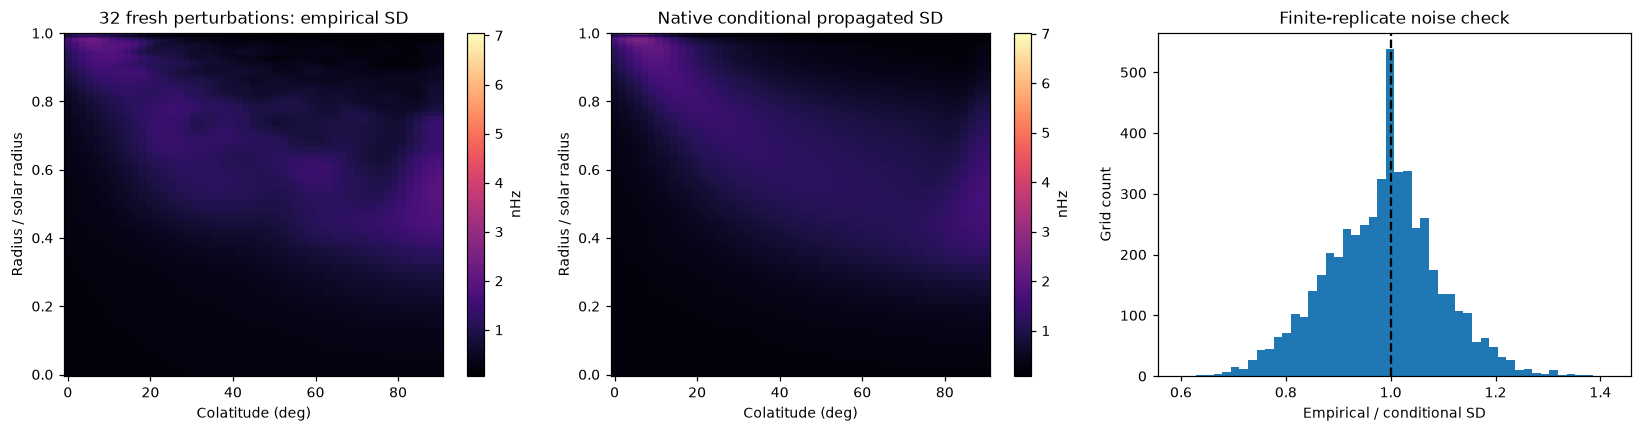

{
  "role": "fresh cleaned measurements; original method reference is not truth",
  "runtime_seconds": 28.7951832000399,
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "rotation_max_abs_nHz": 6.9802183588763e-08,
      "observation_weighted_rms": 1.1936132279167608
    },
    "thresholds": {
      "rotation_max_abs_nHz": {
        "comparison": "<=",
        "boundary": 0.001
      },
      "observation_weighted_rms": {
        "comparison": "<=",
        "boundary": 1.2
      }
    },
    "errors": []
  },
  "adjoint_relative_error": 1.036931671369147e-15,
  "max_field_original_difference_nHz": 0.017236849722223724,
  "max_error_original_difference_nHz": 3.161512226101948e-05,
  "ablation": [
    {
      "label": "iterations: k=250, mu=3, dr=0.06",
      "iterations": 250,
      "tradeoff": 3.0,
      "width": 0.06,
      "field_relative_change": 0.019548672303057565,
      "weighted_rms": 1.2328926123560198,
      "mean_formal_error": 0.4952570750609725

In [6]:
rng=np.random.default_rng(2902);perturbations=[]
for repeat in range(32):
    perturbed=data['splittings']+rng.normal(size=29617)*sigma
    recovery=apply_measurements(con,diagnostics['V'],diagnostics['coefficients'],perturbed).reshape(101,51)
    perturbations.append(recovery-field)
deviation=np.stack(perturbations);empirical=deviation.std(axis=0,ddof=1)
fig,ax=plt.subplots(1,3,figsize=(15,4))
for a,z,title in zip(ax[:2],[empirical,err],['32 fresh perturbations: empirical SD','Native conditional propagated SD']):
    m=a.pcolormesh(theta,radius,z,shading='auto',cmap='magma');a.set(xlabel='Colatitude (deg)',ylabel='Radius / solar radius',title=title);fig.colorbar(m,ax=a,label='nHz')
ax[2].hist((empirical/err).ravel(),bins=50);ax[2].axvline(1,color='k',ls='--');ax[2].set(xlabel='Empirical / conditional SD',ylabel='Grid count',title='Finite-replicate noise check')
fig.tight_layout();plt.show()
summary=dict(role='fresh cleaned measurements; original method reference is not truth',runtime_seconds=runtime,judge=report,adjoint_relative_error=adjoint_error,max_field_original_difference_nHz=float(np.max(abs(field-upstream['reconstruction'][0]))),max_error_original_difference_nHz=float(np.max(abs(err-upstream['formal_error'][0]))),ablation=ablation,noise_replicates=32,empirical_over_formal_mean=float(np.mean(empirical/err)),notebook_compute_seconds=time.perf_counter()-started)
(root/'notebooks/reference_outputs/fresh_metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(summary,indent=2))